<h1><center> LINEAR REGRESSION MODEL </h1></center>

In [46]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [23]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
df=pd.read_excel(r"C:\Users\ELCOT\Desktop\JananiMurugan\Machine_Learning\Self_Task_ML_Models\Linear_Regression\dataset\house_price_multivariate_dataset.xlsx")
df

,Area_sqft,Bedrooms,Bathrooms,Floor_Number,Age_years,Distance_to_City_km,Distance_to_Metro_km,Parking_Spaces,Has_Garden,Has_Lift,Crime_Rate_per_1000,School_Rating,Price_lakhs
0,3053,4,4,7,30,18.1,6.6,0,0,1,12.5,4,113.7
1,2206,2,3,14,27,20.8,5.3,2,0,1,6.0,6,106.1
2,2363,3,4,9,18,11.3,3.9,1,0,1,12.8,7,123.4
3,2927,2,2,13,15,16.1,6.0,2,0,1,16.1,4,122.0
4,2082,2,2,14,23,23.2,6.5,1,1,1,10.7,8,84.5
5,2605,2,1,8,17,27.4,6.5,1,1,1,10.1,7,97.9
6,2759,3,3,4,15,5.4,2.6,0,1,1,15.2,7,149.9
7,1146,1,1,2,10,28.1,7.8,3,1,1,14.2,6,40.6
8,697,1,1,8,14,1.2,1.9,3,1,1,17.6,8,71.7
9,1345,2,2,2,23,22.8,7.1,1,1,0,2.4,2,38.2


##### Data Quality Check

In [4]:
df.isnull().sum()

Area_sqft               0
Bedrooms                0
Bathrooms               0
Floor_Number            0
Age_years               0
Distance_to_City_km     0
Distance_to_Metro_km    0
Parking_Spaces          0
Has_Garden              0
Has_Lift                0
Crime_Rate_per_1000     0
School_Rating           0
Price_lakhs             0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.head(5)

,Area_sqft,Bedrooms,Bathrooms,Floor_Number,Age_years,Distance_to_City_km,Distance_to_Metro_km,Parking_Spaces,Has_Garden,Has_Lift,Crime_Rate_per_1000,School_Rating,Price_lakhs
0,3053,4,4,7,30,18.1,6.6,0,0,1,12.5,4,113.7
1,2206,2,3,14,27,20.8,5.3,2,0,1,6.0,6,106.1
2,2363,3,4,9,18,11.3,3.9,1,0,1,12.8,7,123.4
3,2927,2,2,13,15,16.1,6.0,2,0,1,16.1,4,122.0
4,2082,2,2,14,23,23.2,6.5,1,1,1,10.7,8,84.5


In [15]:
df.columns.tolist()

['Area_sqft',
 'Bedrooms',
 'Bathrooms',
 'Floor_Number',
 'Age_years',
 'Distance_to_City_km',
 'Distance_to_Metro_km',
 'Parking_Spaces',
 'Has_Garden',
 'Has_Lift',
 'Crime_Rate_per_1000',
 'School_Rating',
 'Price_lakhs']

In [12]:
# To find how many rows and columns
df.shape

(30, 13)

##### Feature and Target selection

In [17]:
# Feature selection
X = df[
[
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Floor_Number",
    "Age_years",
    "Distance_to_City_km",
    "Distance_to_Metro_km",
    "Parking_Spaces",
    "Has_Garden",
    "Has_Lift",
    "Crime_Rate_per_1000",
    "School_Rating"
]
]

# Target selection
y = df[
    "Price_lakhs"
]

In [20]:
pd.concat([X,y],axis=1)

,Area_sqft,Bedrooms,Bathrooms,Floor_Number,Age_years,Distance_to_City_km,Distance_to_Metro_km,Parking_Spaces,Has_Garden,Has_Lift,Crime_Rate_per_1000,School_Rating,Price_lakhs
0,3053,4,4,7,30,18.1,6.6,0,0,1,12.5,4,113.7
1,2206,2,3,14,27,20.8,5.3,2,0,1,6.0,6,106.1
2,2363,3,4,9,18,11.3,3.9,1,0,1,12.8,7,123.4
3,2927,2,2,13,15,16.1,6.0,2,0,1,16.1,4,122.0
4,2082,2,2,14,23,23.2,6.5,1,1,1,10.7,8,84.5
5,2605,2,1,8,17,27.4,6.5,1,1,1,10.1,7,97.9
6,2759,3,3,4,15,5.4,2.6,0,1,1,15.2,7,149.9
7,1146,1,1,2,10,28.1,7.8,3,1,1,14.2,6,40.6
8,697,1,1,8,14,1.2,1.9,3,1,1,17.6,8,71.7
9,1345,2,2,2,23,22.8,7.1,1,1,0,2.4,2,38.2


##### Train_test split

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size =0.2,
    random_state =42
)

In [53]:
# To  view train and test 
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (24, 12)
X_test: (6, 12)
y_train: (24,)
y_test: (6,)


##### Model building and training

In [54]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 0.04,-5.41,10.54,...,12.04,-0.22, 1.9 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Area_sqft','Bedrooms','Bathrooms',...,'Has_Lift','Crime_Rate_per_1000', 'School_Rating']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.897
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


##### Model Prediction

In [55]:
y_pred = model.predict(X_test)
y_pred

array([ 59.04941357, 125.32555167,  78.93199511, 129.7773589 ,
        59.3892073 ,  31.7624619 ])

In [56]:
# to compare with it's actual value
print("Actual value:", y_test.values)
print("Predicted value:",y_pred)

Actual value: [ 60.2 108.8  71.7 117.3  71.7  38.2]
Predicted value: [ 59.04941357 125.32555167  78.93199511 129.7773589   59.3892073
  31.7624619 ]


### Model Evaluation Metrics

In [60]:
# (i). MAE
mae = mean_absolute_error(y_test, y_pred)
print("MAE:",mae)

MAE: 9.355637151618138


In [59]:
# MSE
mse = mean_squared_error(y_test, y_pred)
print("MSE:",mse)

MSE: 112.56690985278738


In [38]:
# (iii).  RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RMSE:",rmse)

RMSE: 20.847361017985847


In [61]:
# (iv).  r2  error
r2 = r2_score(y_test, y_pred)
print("R2:",r2)

R2: 0.849017923598542


##### Actual vs Predicted Results

In [62]:
results = pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred
})
print(results)

    Actual   Predicted
27    60.2   59.049414
15   108.8  125.325552
23    71.7   78.931995
17   117.3  129.777359
8     71.7   59.389207
9     38.2   31.762462


##### Actual vs predicted plot

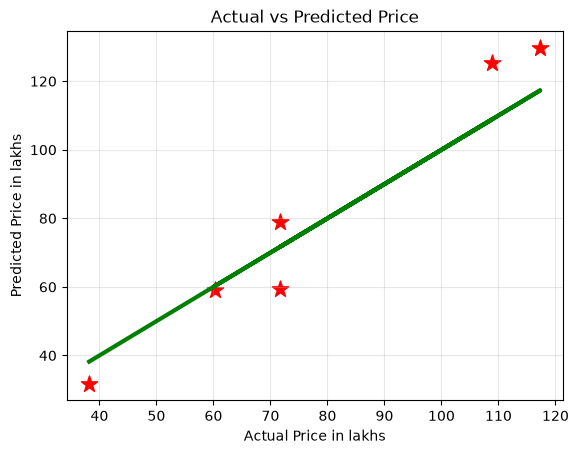

In [69]:
plt.scatter(y_test, y_pred, color="red",marker="*", s=150)
plt.plot(y_test, y_test, color="green", linewidth=3)

plt.xlabel("Actual Price in lakhs")
plt.ylabel("Predicted Price in lakhs")
plt.title("Actual vs Predicted Price")

plt.grid(True, alpha=0.3)
plt.show()